# 003. Question Answering on Movie Knowledge Graphs (MetaQA)

COMP9444 Project | Group: Deep Learners

## 1. Introduction, Motivation and Problem Statement

As Natural Language Processing (NLP) models continue to develop throughout the evolution of artificial intelligence, it has become a key area of research in the fields of automation, with applicable use cases in Recommender Systems, Digital Assistants and Customer Service systems.

Our purpose for Project 003 is to train an AI model on a large knowledge graph of movie facts so that it is able to answer natural language questions.

Two properties make Project 003 nuanced and motivating:

1. **Varied questions.** As with any NLP task, test questions are not linear and uniform, which challenges the model to react dynamically to them.
2. **Multi-hop reasoning.** Each extra hop chains together another relation in the knowledge graph, and sequential hops compound the difficulty for the model to reason.

We need to first analyse and understand what exactly the MetaQA knowledge base contains, and also what it lacks, which will influence our design of the base model's architecture, and of the complex model by extension.

## 2. Data Sources

MetaQA (MoviE Text Audio QA) is a benchmark of more than 400,000 movie-related questions created by Zhang et al. It is released under a Creative Commons public license.

* **Knowledge base:** All questions are generated from the knowledge base `kb.txt`. The knowledge base contains one relationship per line in the form `node|edge|node`.
* **Question description:** The 1-hop questions come from WikiMovies, with ambiguous entities removed. The 2-hop and 3-hop questions are generated from the same knowledge base using 21 (2-hop) and 15 (3-hop) question types with 10 text templates each.
* **Question structure:** Each question line is in the form `question<TAB>answer`. For questions with several answers, the format is extended to `question<TAB>answer1|answer2|...`.

Example:

```
what movies are about [ginger rogers]<TAB>Top Hat|Kitty Foyle|The Barkleys of Broadway
```

## 3. Exploratory Analysis of Data

In analysing the dataset, we looked at the MetaQA knowledge base and its question files.

### 3.1 The knowledge base (`kb.txt`)

The knowledge base contains 134,741 lines written as `node|edge|node`, for example `Kismet|directed_by|William Dieterle`. This makes the knowledge base a **directed, labelled multigraph** with 43,234 nodes, of which 16,427 are movies, and 9 relation types.

The 9 relation types are:

`directed_by` · `written_by` · `starred_actors` · `release_year` · `in_language` · `has_genre` · `has_tags` · `has_imdb_rating` · `has_imdb_votes`

The nodes are written as plain strings with no IDs or types. They fall into eight implicit categories:

`movies` · `people` · `years` · `genres` · `languages` · `tags` · `rating_labels` · `vote_labels`

Every edge points from a movie to one of its attributes, and nothing points back.

The spread of edges and nodes is not even. We specifically identified a major skew in the data: language, IMDb ratings and votes are not sufficiently provided, which will likely affect the performance of our trained model in these areas.

### 3.2 The question files

The 1-hop, 2-hop and 3-hop questions are each split into train, dev and test, with about 96,000, 119,000 and 114,000 training questions respectively, as listed in the README.txt file.

|       |  1-hop |   2-hop |   3-hop |
|-------|-------:|--------:|--------:|
| Train | 96,106 | 118,980 | 114,196 |
| Dev   |  9,992 |  14,872 |  14,274 |
| Test  |  9,947 |  14,872 |  14,274 |

The training data is roughly 8 to 10 times larger than the dev and test data.

Each line in the training files contains a question with the topic entity in square brackets, followed by one or more answers. Example:

```
what movies are about [ginger rogers]<TAB>Top Hat|Kitty Foyle|The Barkleys of Broadway
```

### 3.3 Question types

Each hop also contains different question types, with the type named after the path the question follows.

**Hop 1**

| #  | Question type         |
|----|-----------------------|
| 1  | `movie_to_year`       |
| 2  | `movie_to_director`   |
| 3  | `movie_to_actor`      |
| 4  | `movie_to_writer`     |
| 5  | `movie_to_genre`      |
| 6  | `writer_to_movie`     |
| 7  | `actor_to_movie`      |
| 8  | `movie_to_tags`       |
| 9  | `director_to_movie`   |
| 10 | `tag_to_movie`        |
| 11 | `movie_to_language`   |
| 12 | `movie_to_imdbrating` |
| 13 | `movie_to_imdbvotes`  |

**Hop 2**

| #  | Question type                   |
|----|---------------------------------|
| 1  | `actor_to_movie_to_director`    |
| 2  | `actor_to_movie_to_writer`      |
| 3  | `actor_to_movie_to_actor`       |
| 4  | `actor_to_movie_to_year`        |
| 5  | `actor_to_movie_to_genre`       |
| 6  | `actor_to_movie_to_language`    |
| 7  | `director_to_movie_to_writer`   |
| 8  | `director_to_movie_to_actor`    |
| 9  | `director_to_movie_to_director` |
| 10 | `director_to_movie_to_year`     |
| 11 | `director_to_movie_to_genre`    |
| 12 | `director_to_movie_to_language` |
| 13 | `writer_to_movie_to_director`   |
| 14 | `writer_to_movie_to_actor`      |
| 15 | `writer_to_movie_to_writer`     |
| 16 | `writer_to_movie_to_year`       |
| 17 | `writer_to_movie_to_genre`      |
| 18 | `writer_to_movie_to_language`   |
| 19 | `movie_to_director_to_movie`    |
| 20 | `movie_to_writer_to_movie`      |
| 21 | `movie_to_actor_to_movie`       |

**Hop 3**

| #  | Question type                            |
|----|------------------------------------------|
| 1  | `movie_to_actor_to_movie_to_director`    |
| 2  | `movie_to_actor_to_movie_to_writer`      |
| 3  | `movie_to_actor_to_movie_to_year`        |
| 4  | `movie_to_actor_to_movie_to_genre`       |
| 5  | `movie_to_actor_to_movie_to_language`    |
| 6  | `movie_to_writer_to_movie_to_director`   |
| 7  | `movie_to_writer_to_movie_to_actor`      |
| 8  | `movie_to_writer_to_movie_to_year`       |
| 9  | `movie_to_writer_to_movie_to_genre`      |
| 10 | `movie_to_writer_to_movie_to_language`   |
| 11 | `movie_to_director_to_movie_to_writer`   |
| 12 | `movie_to_director_to_movie_to_actor`    |
| 13 | `movie_to_director_to_movie_to_year`     |
| 14 | `movie_to_director_to_movie_to_genre`    |
| 15 | `movie_to_director_to_movie_to_language` |

These categories are matched to each question in the qtype files given in MetaQA, and help analyse the data received from trained models. For example, the 3rd line in `1-hop/qa_test_qtype.txt` identifies the question type of the 3rd question in `1-hop/vanilla/qa_test.txt`, `1-hop/ntm/qa_test.txt` and `1-hop/audio/qa_test.npz`.

It is also important to mention that although dev and test are smaller than train by roughly a factor of 10, they still contain the same ratio of question types.

### 3.4 Pre-processing

* **Entity mapping.** We first mapped each entity to a numerical value. This helps speed up the model's processing time compared to using the entity names as text.
* **Bidirectional edges.** The edges in the knowledge base are one-directional, so a person like William Dieterle has 17 incoming edges and no outgoing ones, and the model effectively cannot travel back through the knowledge graph. To account for this, we also added a reverse copy of every edge as its own relation. This gives the knowledge base bidirectional edges that help the model traverse the graph.
* **Spare edges.** Tags [has_imdb_rating] and [has_imdb_votes] are sparse in the dataset, present in training question but not in testing questions, hence, we treated the respective result as N/A as it holds no validity.

# 4. Models and/or Methods

## 4.1 Baseline Model
### 4.1.1 Overview
There are two stages in the baseline model:

1. Question classification using TF-IDF and Logistic Regression
2. Answer retrieval using knowledge graph traversal

The question classifier predicts the relationship structure required to answer a question, while graph traversal retrieves the entities from the knowledge graph.

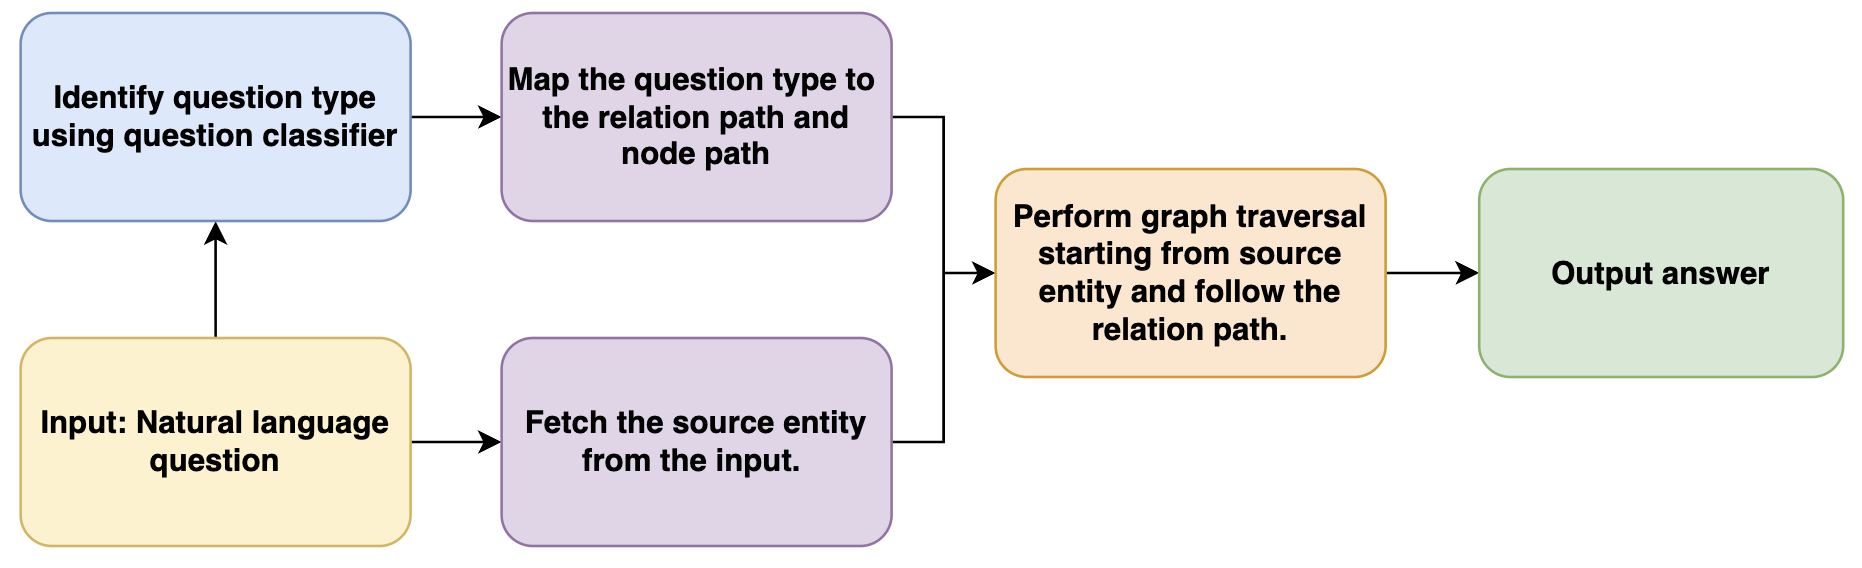
(Figure: Architecture Diagram)

### 4.1.2 Data Preprocessing
Data preprocessing is broken down into two steps:

1. Constructing a knowledge graph using the data in `kb.txt`.
2. Loading questions, question types and answers, and organising them into dictionaries and arrays, such that it is easy to access the data later on in training and testing.

In step 1 of preprocessing, we first create an empty adjacency list as our graph G. As we read through each line `entity1|relation|entity2` of `kb.txt`, we use `split(|)` to obtain the entities and their relationship. We then insert the relationship into a node mapping that identifies the node type of `entity1` and `entity2`, such that we can add `node1 = (node_type1, entity1)` and `node2 = (node_type2, entity2)` to the graph. In terms of the edges, our baseline model sets the graph to be bidirectional, allowing information to be accessed in both ways, so, we would add edges `(node2, relation)` and `(node1, relation)` to `node1` and `node2` respectively.

For example, given the data “Flags of Our Fathers|written_by|Paul Haggis”, our nodes would be `("movie", "Flags of Our Fathers")` and `("person", "Paul Haggis")`, and the edges would be appended to each node's list:
```python
G[("movie", "Flags of Our Fathers")].append((("person", "Paul Haggis"), "written_by"))
G[("person", "Paul Haggis")].append((("movie", "Flags of Our Fathers"), "written_by"))
```

In entity to node type mapping, we considered that it is possible for individuals to have the roles of “director”, “writer” and “actor”, if we represents all human-related roles as individual nodes, there would be many duplicated individuals in the graph. Hence, during the preprocessing stage, the model represents all human-related roles as person node type, avoiding the same individual to be represented as separate role-specific entities.

Before training the Question Classifier, we always normalise the questions by replacing all entity names [XXX] with an entity token, “ENTITY”, such that Logistic Regression and TF-IDF (Term Frequency-Inverse Document Frequency) does not learn the question types based off the specific entities, instead, they model learns the phrasing of the questions.

In [2]:
from collections import defaultdict
import re
import numpy as np
import matplotlib.pyplot as plt
import base64
import seaborn as sns
import pandas as pd
import time

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import f1_score

QS = 0
TYPES = 1
ANS = 2

In [3]:
class Graph:
    def __init__(self):
        self.relation_node_type_mapping = {
            "directed_by": ("movie", "person"),
            "starred_actors": ("movie", "person"),
            "has_genre": ("movie", "genre"),
            "in_language": ("movie", "language"),
            "release_year": ("movie", "year"),
            "has_tags": ("movie", "tag"),
            "has_imdb_rating": ("movie", "imdbrating"),
            "written_by": ("movie", "person"),
            "has_imdb_votes": ("movie", "imdbvotes"),
        }

        node_types = [
            'movie', 'person', 'genre', 'language',
            'year', 'tag', 'imdbrating', 'imdbvotes'
        ]

        self.adj_list = defaultdict(list)
        self.node_types = {t: set() for t in node_types}

    def add_entity(self, node_u, node_type=None):
        # Add an entity to the graph if it doesn't already exist.
        # If given the type of entity, store it in the node_types dictionary.
        if node_u not in self.adj_list:
            self.adj_list[node_u] = []

        if node_type and node_type in self.node_types:
            self.node_types[node_type].add(node_u)

    def add_relation(self, u, v, relation):
        # Add a relation between two entities in the graph.
        u_type, v_type = self.relation_node_type_mapping[relation]
        u_node = (u_type, u)
        v_node = (v_type, v)

        self.add_entity(u_node, u_type)
        self.add_entity(v_node, v_type)
        self.adj_list[u_node].append((v_node, relation))
        self.adj_list[v_node].append((u_node, relation))

    def get_relation(self, node_u, node_v):
        # Get the relation between two entities if it exists.
        for neighbour, relation in self.get_neighbours(node_u):
            if neighbour == node_v:
                return relation
        return None

    def get_related_entities(self, node, relation):
        # Get all entities related to node by the specified relation.
        entities = []
        for nbr, rel in self.adj_list.get(node, []):
            if rel == relation:
                entities.append(nbr)

        return entities

    def get_neighbours(self, node):
        return self.adj_list.get(node, [])

In [4]:
class Preprocess:
    N_HOPS = 3

    def __init__(self):
        self.graph = Graph()
        self.splits = ["train", "dev", "test"]
        self.folders = ["vanilla", "ntm"]
        self.relations = set()

        self.qs_types = {
            data_type: {hop: [] for hop in range(1, self.N_HOPS + 1)}
            for data_type in self.splits
        }

        self.questions = {
            split: {
                hop: {folder: [] for folder in self.folders}
                for hop in range(1, self.N_HOPS + 1)
            }
            for split in self.splits
        }

        self.answers = {
            split: {
                hop: {folder: [] for folder in self.folders}
                for hop in range(1, self.N_HOPS + 1)
            }
            for split in self.splits
        }

    def get_graph(self):
        return self.graph

    def set_graph(self, graph):
        self.graph = graph

    def get_questions(self):
        return self.questions

    def set_questions(self, questions):
        self.questions = questions

    def get_answers(self):
        return self.answers

    def set_answers(self, answers):
        self.answers = answers

    def get_question_types(self):
        return self.qs_types

    def get_relations(self):
        return self.relations

    def get_data(self, data_type):
        # Retrieve the specified data type (training, validation, or test) from
        # the preprocessed data.
        questions = []
        qs_types = []
        answers = []

        for hop in range(1, self.N_HOPS + 1):
            hop_types = self.qs_types[data_type][hop]

            for folder in self.folders:
                hop_questions = self.questions[data_type][hop][folder]
                hop_answers = self.answers[data_type][hop][folder]

                questions.extend(hop_questions)
                answers.extend(hop_answers)

                if not hop_questions:
                    continue

                if len(hop_questions) != len(hop_types):
                    raise ValueError(
                        f"Question type mismatch: {data_type}, "
                        f"{hop}-hop, {folder}: "
                        f"{len(hop_questions)} questions vs "
                        f"{len(hop_types)} types"
                    )

                qs_types.extend(hop_types)

        return questions,  qs_types, answers

    def preprocess(self):
        # Preprocess the knowledge base data and add it to the graph.
        self.add_entities()
        self.add_relations()
        self.add_question_types()
        self.add_questions()

    def add_entities(self):
        # Add the knowledge base data into the graph as entities.
        with open('MetaQA/entity/kb_entity_dict.txt', 'r') as f:
            for line in f:
                u = re.sub(r'^[0-9 ]+', '', line.strip())
                self.graph.add_entity(u)

    def add_relations(self):
        # Add the knowledge base data into the graph as entities and relations.
        with open('MetaQA/kb.txt', 'r') as f:
            for line in f:
                u, relation, v = line.strip().split('|')
                self.graph.add_relation(u, v, relation)
                self.relations.add(relation)

    def add_question_types(self):
        # Store the question types from each hop's question_types.txt file into
        # a list.
        for split in self.splits:
            for i in range(1, self.N_HOPS + 1):
                filename = f"MetaQA/{i}-hop/qa_{split}_qtype.txt"
                with open(filename, "r") as f:
                    self.qs_types[split][i] = [line.strip() for line in f]

    def add_questions(self):
        # Load the question-answer pairs from each hop's text file and store
        # them in the questions and answers dictionaries.
        for data_type in self.splits:
            for i in range(1, self.N_HOPS + 1):
                for folder in self.folders:
                    qs, ans = self.add_qs_to_hop(i, folder, data_type)
                    self.questions[data_type][i][folder] = qs
                    self.answers[data_type][i][folder] = ans

    def add_qs_to_hop(self, hop, folder, split):
        # Load the question-answer pairs from the specified hop's text file.
        questions = []
        answers = []
        filename = f'MetaQA/{hop}-hop/{folder}/qa_{split}.txt'
        with open(filename, 'r') as f:
            rows = [line.strip() for line in f if line.strip()]
            for line in rows:
                question, answer = line.split('\t')
                answer_list = answer.split('|')
                questions.append(question)
                answers.append(answer_list)

        return questions, answers

### 4.1.3 Question Classifier
The Question Classifier is made up of TF-IDF and Logistic Regression.

**Why choose to use TF-IDF?**

The TF-IDF measures how frequently a word appears in a specific document, as well as measuring the uniqueness of words across the entire data. Using the rareness of words, TF-IDF can scale down common words like "the," "is," or "and", and help the classifier to focus on important words that acts as important clues for the question type. For instance, important question words could be directed by, actors, language, written by, who, what, where etc.

**Why choose to use Logistic Regression?**

We chose Logistic Regression as it is a lightweight linear classifier and it is suitable for high-dimensional, sparse TF-IDF features. It learns feature weights that distinguish question types and predicts the most likely class.

In [5]:
class Question_Classifer:
    def __init__(self):
        self.model = LogisticRegression(
            solver="saga",
            random_state=42,
            max_iter=300
        )

        self.vectorizer = TfidfVectorizer(
            ngram_range=(1, 2),
            stop_words=None,
            min_df=5,
            max_features=40000
        )

    def train(self, questions, question_types):
        # Fit the question classifier model using the provided questions and
        # their corresponding types.
        normalised_questions = self.normalise_questions(questions)
        X_train = self.vectorizer.fit_transform(normalised_questions)
        self.model.fit(X_train, question_types)

    def normalise_questions(self, questions):
        # Replaces the entities in every question with ENTITY.
        results = []
        for question in questions:
            results.append(self.normalise_question(question))

        return results

    def normalise_question(self, question):
        # Replace the specific entity in the question with ENTITY, such that
        # during training, validation or testing, the classifier can focus on
        # the words that indicate the relation path, rather than the
        # associations with particular entity names.
        return re.sub(
            r"\[[^\]]+\]",
            "ENTITY",
            question
        )

    def predict(self, question):
        # Predict the type of a given question using the trained model.
        normalised_question = self.normalise_question(question)
        features = self.vectorizer.transform([normalised_question])
        return self.model.predict(features)[0]

    def evaluate(self, questions, labels):
        # Evaluate the model on a test dataset and print the classification
        # report and accuracy.
        normalised_questions = self.normalise_questions(questions)
        features = self.vectorizer.transform(normalised_questions)
        predictions = self.model.predict(features)
        accuracy = accuracy_score(labels, predictions)
        report = classification_report(labels, predictions, zero_division=0)

        return accuracy, report, predictions

    def count_params(self):
        # Returns the number of params used in the model
        return self.model.coef_.size + self.model.intercept_.size

### 4.1.4 Question Answering and Graph Traversal
The baseline's architecture diagram provides a basic idea of the flow in question answering.

Graph traversal begins with the extracted source entity, represented as a tuple containing its node type and entity name. For each relation in the predicted relation path, the algorithm retrieves neighbouring entities connected by that relation and filters them according to the expected target node type. The traversal maintains the candidate paths so that multiple valid neighbours can be explored at each hop, moreover, it helps to prevent immediate backtracking to the previous node via the same relation, such that trivial reverse traversal is avoided. After all relations have been visited, the names of the final reachable entities are collected into a set, which forms the predicted answer set.

For example, let the question be “the films that share directors with the film [Catch Me If You Can] were in which languages”:
| Source | Target | Result |
| --- | --- | --- |
| Question | Source Entity | Catch Me If You Can |
| Question | Question type | `movie_to_director_to_movie_to_language` |
| Question type | Role path | `[movie, director, movie, language]` |
| Role path | Node path | `[movie, person, movie, language]` |
| Role path | Relation path |`[directed_by, directed_by, in_language]`|

The graph traversal would start at the source entity:

Iteration 1:
- Current relation: `directed_by`
- Get all directors that are related to the node `("movie", "Catch Me If You Can")` via relation `directed_by`. Set the directors as the next group of entities for traversal.

Iteration 2:
- Current relation: `directed_by`
- For each director `d` in the current group of entities, find all movies related to `(person, d)` via `directed_by` and store each movies as the next group of entities.

Iteration 3:
- Current erlation: `in_language`
- For each movie in current group of entities, find all languages related to the movie via `in_language`, and store the languages as the next group of entities.

Since we have already reached the end of the relation path, this means the current entities are the final answers for the 3-hop question.

In [6]:
class Baseline:
    """
    Baseline model for COMP9444 project.
    """

    ROLE_TO_RELATION = {
        "director": "directed_by",
        "writer": "written_by",
        "actor": "starred_actors",
        "genre": "has_genre",
        "language": "in_language",
        "year": "release_year",
        "tag": "has_tags",
        "imdbrating": "has_imdb_rating",
        "imdbvotes": "has_imdb_votes",
    }

    PERSON_ROLES = {"director", "writer", "actor"}

    def __init__(self, graph, question_classifier):
        self.graph = graph
        self.question_classifier = question_classifier

    def evaluate(self, questions, answers):
        # Evaluate the model's performance on a set of questions and their
        # corresponding answers, returning the exact-match accuracy.
        if not questions:
            return 0.0

        n_correct = 0
        for question, true_answers in zip(questions, answers):
            if set(self.predict(question)) == set(true_answers):
                n_correct += 1

        return n_correct / len(questions)

    def predict(self, question):
        # Predict the answer to a given question by classifying it and
        # traversing the graph.
        entities, node_path, relation_path = self.classify_question(question)
        return self.answer_question(entities, node_path, relation_path)

    def classify_question(self, question):
        # Identify the type of question and extract the starting entities and
        # relation path.
        entities = self.extract_entities(question)
        question_type = self.question_classifier.predict(question)
        relation_path, node_path = self.get_relation_path(question_type)

        return entities, node_path, relation_path

    def extract_entities(self, question):
        # Extract entities from the question using regex.
        return re.findall(r'\[([^\]]+)\]', question)

    def get_relation_path(self, question_type):
        # Given the question type, remove the "_to_" from the string and obtain
        # the relation path.
        role_path = [
            "tag" if role == "tags" else role
            for role in question_type.split("_to_")
        ]

        node_path = [
            "person" if role in self.PERSON_ROLES else role
            for role in role_path
        ]

        relation_path = []

        for source_role, target_role in zip(role_path, role_path[1:]):
            if source_role == "movie":
                role = target_role
            elif target_role == "movie":
                role = source_role

            relation_path.append(self.ROLE_TO_RELATION[role])

        return relation_path, node_path

    def answer_question(self, entities, node_path, relation_path):
        # Given the starting entities and relation path, traverse the graph to
        # find the answer entities.
        paths = [
            (None, None, (node_path[0], entity))
            for entity in entities
        ]

        for rel, target in zip(relation_path, node_path[1:]):
            next_paths = []

            for prev, prev_rel, curr in paths:
                nbrs = self.valid_nbrs(curr, prev, prev_rel, rel, target)
                next_paths.extend((curr, rel, nbr) for nbr in nbrs)

            paths = next_paths

        return {curr[1] for _, _, curr in paths}

    def valid_nbrs(self, curr, prev, prev_rel, relation, target):
        # Filter neighbours by expected node type and prevent immediate backtracking
        # through the same relation.
        nbrs = self.graph.get_related_entities(curr, relation)

        valid_nbrs = []
        for nbr in nbrs:
            if nbr[0] == target and not (nbr == prev and relation == prev_rel):
                valid_nbrs.append(nbr)

        return valid_nbrs


Running the baseline:

In [10]:
print("\n=== Preprocessing ===")
preprocess = Preprocess()
print("Start preprocessing...")
preprocess.preprocess()
print("Preprocessing completed.")

graph = preprocess.get_graph()
data = {
    "train": preprocess.get_data("train"),
    "dev": preprocess.get_data("dev"),
    "test": preprocess.get_data("test")
}

print("\n=== Question Classifier ===")
question_classifier = Question_Classifer()
print("Start question classifier training...")
start_time = time.perf_counter()
question_classifier.train(data["train"][QS], data["train"][TYPES])
train_time = time.perf_counter() - start_time
print(f"Question classifier training completed in {train_time:.4f}s.")

print(f"Number of params: {question_classifier.count_params():,}")

predictions = []
for split in ["dev", "test"]:
    accuracy, report, pred = question_classifier.evaluate(
        data[split][QS],
        data[split][TYPES]
    )

    if split == "dev":
        predictions = pred

    print(f"Classification accuracy for {split} data: {accuracy:.2%}")
    print(report)

print("\n=== Baseline ===")
baseline = Baseline(graph, question_classifier)

print("\n### Final Test Evaluation ###")
start_eval = time.perf_counter()
accuracy = baseline.evaluate(data["test"][QS], data["test"][ANS])
eval_time = time.perf_counter() - start_eval
print(
    f"Accuracy: {accuracy:.2%} "
    f"Test evaluation time: {eval_time:.4f}s"
    f" ({eval_time / len(data['test'][QS]) * 1000:.2f} ms/question)"
)


=== Preprocessing ===
Start preprocessing...
Preprocessing completed.

=== Question Classifier ===
Start question classifier training...
Question classifier training completed in 54.7337s.
Number of params: 68,943
Classification accuracy for dev data: 98.46%
                                        precision    recall  f1-score   support

                        actor_to_movie       1.00      1.00      1.00      1810
               actor_to_movie_to_actor       1.00      1.00      1.00      1960
            actor_to_movie_to_director       0.96      1.00      0.98      1830
               actor_to_movie_to_genre       0.94      0.99      0.96      1564
            actor_to_movie_to_language       0.92      0.94      0.93       578
              actor_to_movie_to_writer       0.95      0.98      0.97      1742
                actor_to_movie_to_year       1.00      0.99      0.99      1962
                     director_to_movie       1.00      1.00      1.00      1080
            directo

## 5. Results and Analysis: Baseline Model

We evaluate the **complete predicted answer set** against the gold answer set; a question is correct only if the two sets are equal. The test population below combines MetaQA Vanilla and NTM questions from all three hop levels. This section uses the trained Model 1 instance from Section 4 and the same graph and test split. It recomputes the group notebook's saved 96.14% overall result at commit `41ff6de` and exposes its denominators and subsets.

### 5.1 Exact-set accuracy by hop and wording


In [7]:
rows = []
predicted_sets = {}
for hop in (1, 2, 3):
    for wording in ("vanilla", "ntm"):
        questions = preprocess.questions["test"][hop][wording]
        gold_sets = preprocess.answers["test"][hop][wording]
        assert len(questions) == len(gold_sets), f"{hop}-hop {wording}: question/answer count mismatch"
        predictions = [set(baseline.predict(q)) for q in questions]
        predicted_sets[(hop, wording)] = predictions
        correct = sum(pred == set(gold) for pred, gold in zip(predictions, gold_sets))
        rows.append({
            "hop": hop,
            "wording": wording,
            "correct": correct,
            "total": len(questions),
            "exact_set_accuracy": correct / len(questions),
        })

result_table = pd.DataFrame(rows)
display(result_table)
overall_correct = int(result_table.correct.sum())
overall_total = int(result_table.total.sum())
print(f"Overall: {overall_correct:,} / {overall_total:,} = {overall_correct / overall_total:.2%}")
assert (overall_correct, overall_total) == (75169, 78186)
assert abs(overall_correct / overall_total - accuracy) < 1e-12

,hop,wording,correct,total,exact_set_accuracy
0,1,vanilla,9407,9947,0.945712
1,1,ntm,9386,9947,0.943601
2,2,vanilla,14334,14872,0.963825
3,2,ntm,13501,14872,0.907813
4,3,vanilla,14274,14274,1.000000
5,3,ntm,14267,14274,0.999510


Overall: 75,169 / 78,186 = 96.14%


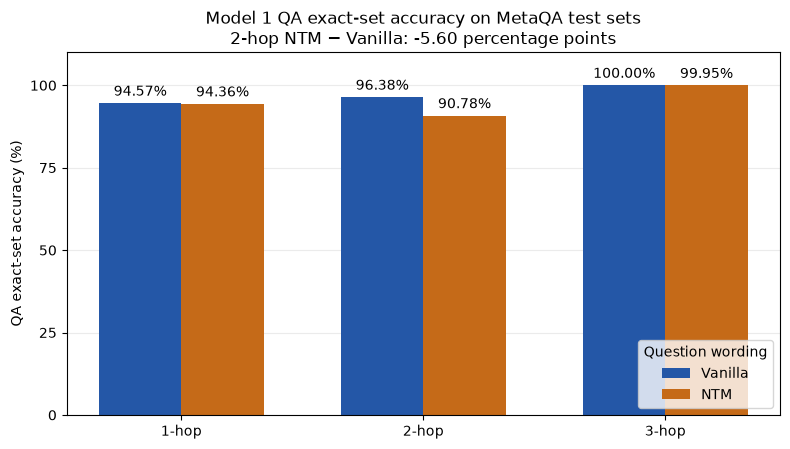

In [8]:
# Treat hop levels as discrete groups; percentages come from the table above.
vanilla = result_table[result_table.wording == "vanilla"].sort_values("hop")
ntm = result_table[result_table.wording == "ntm"].sort_values("hop")
assert vanilla.hop.tolist() == ntm.hop.tolist() == [1, 2, 3]
vanilla_values = 100 * vanilla.exact_set_accuracy.to_numpy()
ntm_values = 100 * ntm.exact_set_accuracy.to_numpy()
x = np.arange(3)
width = 0.34

fig, ax = plt.subplots(figsize=(8, 4.6))
vanilla_bars = ax.bar(x - width / 2, vanilla_values, width, label="Vanilla", color="#2457A7")
ntm_bars = ax.bar(x + width / 2, ntm_values, width, label="NTM", color="#C56A18")
ax.bar_label(vanilla_bars, labels=[f"{value:.2f}%" for value in vanilla_values], padding=3)
ax.bar_label(ntm_bars, labels=[f"{value:.2f}%" for value in ntm_values], padding=3)
ax.set_xticks(x, ["1-hop", "2-hop", "3-hop"])
ax.set_ylim(0, 110)
ax.set_yticks([0, 25, 50, 75, 100])
ax.set_ylabel("QA exact-set accuracy (%)")
ax.set_title("Model 1 QA exact-set accuracy on MetaQA test sets\n"
             f"2-hop NTM − Vanilla: {ntm_values[1] - vanilla_values[1]:+.2f} percentage points")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(title="Question wording", loc="lower right")
fig.tight_layout()
plt.show()


### 5.2 Paired 2-hop wording diagnostic

The Vanilla and NTM test files align row by row. We first verify that each pair has the same bracketed starting entity and gold answer, then compare the **trained model's** exact-set outcomes. We also traverse the same graph using the provided gold question type. This **gold-type oracle is diagnostic**, not a score for the trained classifier.

One paired test example starts at **[David Mandel]** and has the same gold answer, **{German}**, in both files:

| Stage | Vanilla wording | NTM wording |
| --- | --- | --- |
| Question | “what are the primary languages in the movies directed by [David Mandel]” | “What are the main languages in [David Mandel] films” |
| Predicted type | `director_to_movie_to_language` | `actor_to_movie_to_language` |
| Traversal path | director → movie → language | actor → movie → language |
| Predicted answer set | {German} | empty set |

The NTM sentence lacks an explicit director cue. This pair illustrates how wording can alter the predicted type, path and answer; **one example does not establish the cause of every 2-hop error**. The code below verifies the pair counts and prints this example from the test files.


In [9]:
from collections import Counter

hop = 2
v_qs = preprocess.questions["test"][hop]["vanilla"]
n_qs = preprocess.questions["test"][hop]["ntm"]
v_gold = preprocess.answers["test"][hop]["vanilla"]
n_gold = preprocess.answers["test"][hop]["ntm"]
gold_types = preprocess.qs_types["test"][hop]
assert len(v_qs) == len(n_qs) == len(v_gold) == len(n_gold) == len(gold_types)
assert all(set(a) == set(b) for a, b in zip(v_gold, n_gold))
assert all(baseline.extract_entities(a) == baseline.extract_entities(b)
           for a, b in zip(v_qs, n_qs))

paired = Counter()
oracle_correct = 0
for index, (n_q, gold, gold_type) in enumerate(zip(n_qs, n_gold, gold_types)):
    v_ok = predicted_sets[(2, "vanilla")][index] == set(gold)
    n_ok = predicted_sets[(2, "ntm")][index] == set(gold)
    paired[(v_ok, n_ok)] += 1
    relation_path, node_path = baseline.get_relation_path(gold_type)
    oracle_answer = baseline.answer_question(
        baseline.extract_entities(n_q), node_path, relation_path)
    oracle_correct += set(oracle_answer) == set(gold)

print("Both correct:", paired[(True, True)])
print("Vanilla only:", paired[(True, False)])
print("NTM only:", paired[(False, True)])
print("Both wrong:", paired[(False, False)])
print(f"NTM gold-type oracle: {oracle_correct:,} / {len(n_qs):,} = {oracle_correct / len(n_qs):.2%}")
assert [paired[k] for k in ((True, True), (True, False), (False, True), (False, False))] == [13501, 833, 0, 538]
assert oracle_correct == 14334

example_idx = 2
for wording, questions in (("vanilla", v_qs), ("ntm", n_qs)):
    question = questions[example_idx]
    print(wording, question)
    print("predicted type:", baseline.question_classifier.predict(question))
    print("predicted answer:", sorted(predicted_sets[(2, wording)][example_idx]))
print("gold type:", gold_types[example_idx])
print("gold answer:", sorted(set(n_gold[example_idx])))

Both correct: 13501
Vanilla only: 833
NTM only: 0
Both wrong: 538
NTM gold-type oracle: 14,334 / 14,872 = 96.38%
vanilla what are the primary languages in the movies directed by [David Mandel]
predicted type: director_to_movie_to_language
predicted answer: ['German']
ntm What are the main languages in [David Mandel] films
predicted type: actor_to_movie_to_language
predicted answer: []
gold type: director_to_movie_to_language
gold answer: ['German']


### 5.3 Interpretation and limits

On this combined test set, Model 1 obtains **75,169/78,186 = 96.14%** exact-set accuracy. The 1-, 2-, and 3-hop scores are **94.47%**, **93.58%**, and **99.98%**. The 2-hop subset is weakest, so hop count alone does not explain test difficulty.

For aligned 2-hop questions, Vanilla scores **14,334/14,872 = 96.38%**, while differently worded NTM scores **13,501/14,872 = 90.78%**, a **5.60 percentage-point** gap. The paired result has 833 Vanilla-only successes, no NTM-only successes, and 538 pairs wrong in both versions. Supplying the gold question type raises NTM to **14,334/14,872 = 96.38%** with the same graph and starting entities. This locates the observed gap at question-type prediction in this pipeline; the oracle is not a deployable model result. The 538 shared failures persist with the gold type and need case-level analysis before assigning a cause.

The displayed David Mandel NTM question omits an explicit director cue, and the classifier chooses an actor path. It illustrates wording sensitivity, but does not prove that the two phrasings are equally unambiguous. Near-perfect 3-hop accuracy on these files does not establish performance on unseen question templates. The reported results apply to these MetaQA test files and this graph; they do not compare Model 1's exact-set metric with PullNet's Hits@N.


## 6. Results and Analysis: PullNet (Model 2)

### 6.1 Results by hop

PullNet has one model per hop, each tested on the full MetaQA vanilla test set. We score it with **Hits@N**: is at least one correct answer in the model's top N? **Hits@1** (the top answer is correct) is the main score, and we also show **Hits@10**.

In [1]:
# ---- Inputs for the PullNet analysis (sections 6 and 8) ----
# Everything below uses only these two names:
#   pn_scores[hop]  -> {"n", "hits@1", "hits@10"} for hop 1, 2 and 3
#   pn_predictions  -> one dict per 3-hop test question, with keys: question, topic, qtype, gold,
#                      top10 [(entity, score), ...], first_correct_rank (None if not ranked),
#                      gold_retrieved (how many correct answers the model collected)
# For now they are loaded from saved result files. Once the PullNet test cells are in this
# notebook, point these two names at their output instead.
import json
from pathlib import Path
from collections import Counter, defaultdict
import matplotlib.pyplot as plt

PN_SCORE_FILES = {hop: Path(f"pullnet/results/hop{hop}_test_full.json") for hop in (1, 2, 3)}
PN_PREDICTION_FILE = Path("analysis/pullnet_run/predictions/hop3_test.jsonl")

pn_scores = {}
for hop, path in PN_SCORE_FILES.items():
    if not path.exists():
        print(f"not available yet: {path}")
        continue
    data = json.loads(path.read_text())
    metrics = data["results"]["run"]["metrics"]
    pn_scores[hop] = {"n": data["n"], "hits@1": metrics["hits@1"], "hits@10": metrics["hits@10"]}

if PN_PREDICTION_FILE.exists():
    pn_predictions = [json.loads(line) for line in PN_PREDICTION_FILE.open(encoding="utf-8")]
else:
    print(f"not available yet: {PN_PREDICTION_FILE}")
    pn_predictions = []

# Hits@1 (%) reported in the PullNet paper, knowledge-base-only setting (Sun et al., 2019, Table 2)
PN_PAPER_HITS1 = {1: 97.0, 2: 99.9, 3: 91.4}

def pn_pct(x):  # 1 decimal place, but 99.99% must not show as 100.0%
    return f"{100 * x:.2f}%" if 0.9995 <= x < 1 else f"{100 * x:.1f}%"

print(f"{'':6}{'questions':>10}{'Hits@1':>9}{'Hits@10':>9}{'paper Hits@1':>14}")
for hop, s in pn_scores.items():
    print(f"{hop}-hop {s['n']:>10,}{pn_pct(s['hits@1']):>9}{pn_pct(s['hits@10']):>9}{PN_PAPER_HITS1[hop]:>13.1f}%")
print(f"\n3-hop questions with a saved answer list: {len(pn_predictions):,}")

       questions   Hits@1  Hits@10  paper Hits@1
1-hop      9,947    97.0%   99.99%         97.0%
2-hop     14,872    99.2%    99.8%         99.9%
3-hop     14,274    58.5%    94.7%         91.4%

3-hop questions with a saved answer list: 14,274


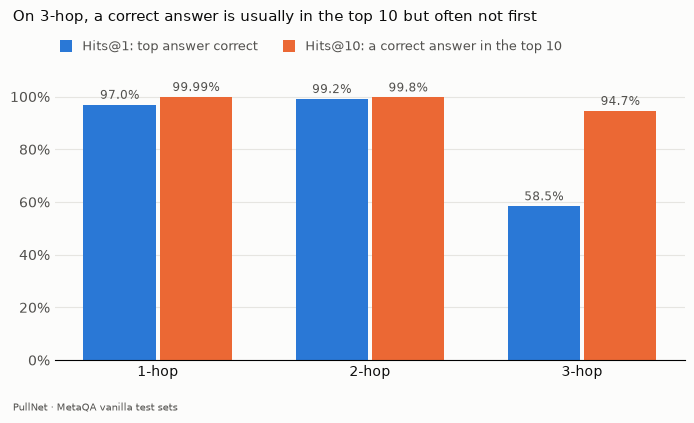

In [2]:
PN_SURFACE, PN_INK, PN_INK_2, PN_GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
PN_BLUE, PN_ORANGE, PN_GREY = "#2a78d6", "#eb6834", "#b5b4ae"
PN_FIG_DIR = Path("analysis/figures")
PN_FIG_DIR.mkdir(parents=True, exist_ok=True)

def pn_style(ax, grid_axis="y"):
    ax.set_facecolor(PN_SURFACE)
    ax.tick_params(colors=PN_INK_2, length=0)
    ax.grid(axis=grid_axis, color=PN_GRID, zorder=0)
    for side in ("top", "right", "left" if grid_axis == "y" else "bottom"):
        ax.spines[side].set_visible(False)

pn_hops = sorted(pn_scores)
fig, ax = plt.subplots(figsize=(7, 4.2), facecolor=PN_SURFACE)
pn_style(ax)
for i, (label, key, color) in enumerate([("Hits@1: top answer correct", "hits@1", PN_BLUE),
                                         ("Hits@10: a correct answer in the top 10", "hits@10", PN_ORANGE)]):
    xs = [hop - 1 + (i - 0.5) * 0.36 for hop in pn_hops]
    values = [pn_scores[hop][key] for hop in pn_hops]
    bars = ax.bar(xs, [100 * v for v in values], width=0.34, color=color, label=label, zorder=2)
    ax.bar_label(bars, labels=[pn_pct(v) for v in values], padding=2, fontsize=8.5, color=PN_INK_2)
ax.set_xticks([hop - 1 for hop in pn_hops], [f"{hop}-hop" for hop in pn_hops], color=PN_INK, fontsize=10)
ax.set_ylim(0, 110)
ax.set_yticks(range(0, 101, 20), [f"{t}%" for t in range(0, 101, 20)])
ax.legend(loc="lower left", bbox_to_anchor=(-0.01, 1.02), ncol=2, frameon=False, fontsize=9,
          labelcolor=PN_INK_2, handlelength=1, handleheight=1)
fig.suptitle("On 3-hop, a correct answer is usually in the top 10 but often not first",
             x=0.02, ha="left", fontsize=11, color=PN_INK, y=0.965)
fig.text(0.02, 0.01, "PullNet · MetaQA vanilla test sets", fontsize=7.5, color=PN_INK_2)
fig.subplots_adjust(left=0.08, right=0.98, bottom=0.13, top=0.82)
fig.savefig(PN_FIG_DIR / "pullnet_hits_by_hop.png", dpi=200, facecolor=PN_SURFACE)
plt.show()

**What this means:** PullNet is almost perfect on 1-hop and 2-hop questions (Hits@1 97.0% and 99.2%). On 3-hop, only 58.5% of its top answers are correct, but 94.7% of questions have a correct answer somewhere in the top 10. **PullNet almost always finds a correct answer, but often doesn't rank it first.**

Compared with the original PullNet paper (97.0 / 99.9 / 91.4 Hits@1; Sun et al., 2019, Table 2), it matches on 1-hop and 2-hop but is well below on 3-hop.
<!-- Lily: update these numbers after the full re-run (they come from the code outputs) -->

### 6.2 Example: a typical 3-hop mistake

We chose this question because it shows the most common type of mistake (see 6.3), not at random.

> *who starred in the films whose directors also directed [The Savages]*

To answer it, the model has to take three steps through the knowledge graph:

| Step | From | Link | To |
|---|---|---|---|
| 1 | *The Savages* | directed by | Tamara Jenkins |
| 2 | Tamara Jenkins | also directed | *Slums of Beverly Hills* |
| 3 | *Slums of Beverly Hills* | starring | **Alan Arkin, Marisa Tomei, Natasha Lyonne** (the correct answers) |

PullNet's answers:
- **1st: Philip Seymour Hoffman**, an actor in *The Savages* itself
- **2nd: Tamara Jenkins**, the director

Both are only **1 step** from the starting film. The first correct answer is at **rank 12**.

**What this means:** PullNet stopped after one step instead of going all three.
<!-- Lily: update these numbers after the full re-run (they come from the code outputs) -->

In [3]:
# Read the knowledge graph once (used here and in 6.3)
pn_forward = defaultdict(set)   # (subject, relation) -> objects
pn_linked = defaultdict(set)    # entity -> every entity one step away
with open("MetaQA/kb.txt", encoding="utf-8") as f:
    for line in f:
        subject, relation, obj = line.rstrip("\n").split("|")
        pn_forward[subject, relation].add(obj)
        pn_linked[subject].add(obj)
        pn_linked[obj].add(subject)

def pn_link_to_start(start, name):
    links = [rel for rel in ("starred_actors", "directed_by", "written_by", "release_year", "has_genre", "in_language")
             if name in pn_forward.get((start, rel), ())]
    return f"1 step from the start ({', '.join(links)})" if links else "not directly linked to the start"

pn_example = next((p for p in pn_predictions if p["topic"] == "The Savages"
                   and p["qtype"] == "movie_to_director_to_movie_to_actor"), None)
if pn_example is None:
    print("not available yet: The Savages question in pn_predictions")
else:
    print("Question:       ", pn_example["question"])
    print("Correct answers:", ", ".join(pn_example["gold"]))
    for rank, (name, _) in enumerate(pn_example["top10"][:2], start=1):
        print(f"PullNet rank {rank}:  {name}  ->  {pn_link_to_start('The Savages', name)}")
    print("First correct answer at rank:", pn_example["first_correct_rank"])

Question:        who starred in the films whose directors also directed [The Savages]
Correct answers: Alan Arkin, Marisa Tomei, Natasha Lyonne
PullNet rank 1:  Philip Seymour Hoffman  ->  1 step from the start (starred_actors)
PullNet rank 2:  Tamara Jenkins  ->  1 step from the start (directed_by, written_by)
First correct answer at rank: 12


### 6.3 Types of mistakes

We sorted every wrong 3-hop top answer by how it is linked to the starting film in the knowledge graph.

In [4]:
PN_ROLE_LINK = {"director": "directed_by", "writer": "written_by", "actor": "starred_actors",
                "genre": "has_genre", "language": "in_language", "year": "release_year"}
PN_TYPES = {  # key: (label, stopped short?)
    "own":    ("The starting film's own answer\n(e.g. its own actor or release year)", True),
    "middle": ("The person the question goes through\n(e.g. the starting film's director)", True),
    "linked": ("Something else linked\nto the starting film", True),
    "never":  ("Never collected\na correct answer", False),
    "other":  ("Other mix-ups", False),
}

def pn_mistake_type(p):
    # 3-hop question types look like movie_to_director_to_movie_to_actor
    _, middle_role, _, answer_role = p["qtype"].split("_to_")
    start, guess = p["topic"], p["top10"][0][0]
    if p["gold_retrieved"] == 0:
        return "never"
    if guess in pn_forward.get((start, PN_ROLE_LINK[middle_role]), ()):
        return "middle"
    if guess in pn_forward.get((start, PN_ROLE_LINK[answer_role]), ()):
        return "own"
    if guess in pn_linked.get(start, ()):
        return "linked"
    return "other"

pn_wrong = [p for p in pn_predictions if p["hits@1"] == 0]
pn_type_counts = Counter(pn_mistake_type(p) for p in pn_wrong)
pn_short = sum(pn_type_counts[k] for k, (_, short) in PN_TYPES.items() if short)

if not pn_wrong:
    print("not available yet: pn_predictions")
else:
    share = lambda k: f"{pn_type_counts[k]:>6,}  ({pn_type_counts[k] / len(pn_wrong):.0%})"
    print(f"Wrong 3-hop answers: {len(pn_wrong):,} of {len(pn_predictions):,}\n")
    print(f"Stopped short (top answer only 1 step from the starting film): {pn_short:,} ({pn_short / len(pn_wrong):.0%})")
    print(f"  the starting film's own answer:         {share('own')}")
    print(f"  the person the question goes through:   {share('middle')}")
    print(f"  something else linked to the film:      {share('linked')}")
    print(f"Never collected a correct answer:         {share('never')}")
    print(f"Other mix-ups:                            {share('other')}")
    print(f"\nA correct answer was collected (just ranked lower) in "
          f"{1 - pn_type_counts['never'] / len(pn_wrong):.0%} of mistakes")

Wrong 3-hop answers: 5,569 of 14,274

Stopped short (top answer only 1 step from the starting film): 3,331 (60%)
  the starting film's own answer:          2,382  (43%)
  the person the question goes through:      636  (11%)
  something else linked to the film:         313  (6%)
Never collected a correct answer:            428  (8%)
Other mix-ups:                             1,810  (33%)

A correct answer was collected (just ranked lower) in 92% of mistakes


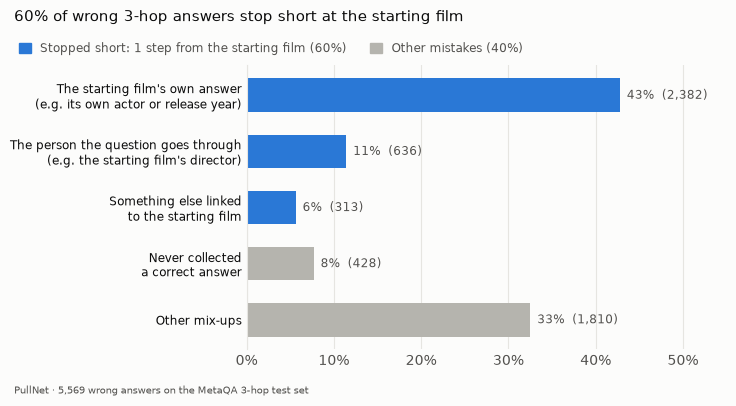

In [5]:
if pn_wrong:
    pn_rows = ["own", "middle", "linked", "never", "other"]
    fig, ax = plt.subplots(figsize=(7.5, 4.0), facecolor=PN_SURFACE)
    pn_style(ax, grid_axis="x")
    ys = list(range(len(pn_rows)))[::-1]
    for y, key in zip(ys, pn_rows):
        share = 100 * pn_type_counts[key] / len(pn_wrong)
        ax.barh(y, share, height=0.6, zorder=2, color=PN_BLUE if PN_TYPES[key][1] else PN_GREY)
        ax.text(share + 0.8, y, f"{share:.0f}%  ({pn_type_counts[key]:,})", va="center", fontsize=8.5, color=PN_INK_2)
    ax.set_yticks(ys, [PN_TYPES[k][0] for k in pn_rows], fontsize=8.5, color=PN_INK)
    ax.set_xlim(0, 55)
    ax.set_xticks(range(0, 51, 10), [f"{t}%" for t in range(0, 51, 10)])
    ax.spines["left"].set_color(PN_GRID)
    short_pct = 100 * pn_short / len(pn_wrong)
    handles = [plt.Rectangle((0, 0), 1, 1, color=PN_BLUE), plt.Rectangle((0, 0), 1, 1, color=PN_GREY)]
    fig.legend(handles, [f"Stopped short: 1 step from the starting film ({short_pct:.0f}%)",
                         f"Other mistakes ({100 - short_pct:.0f}%)"],
               loc="upper left", bbox_to_anchor=(0.012, 0.915), ncol=2, frameon=False, fontsize=8.5,
               labelcolor=PN_INK_2, handlelength=1, handleheight=1)
    fig.suptitle(f"{short_pct:.0f}% of wrong 3-hop answers stop short at the starting film",
                 x=0.02, ha="left", fontsize=11, color=PN_INK, y=0.97)
    fig.text(0.02, 0.01, f"PullNet · {len(pn_wrong):,} wrong answers on the MetaQA 3-hop test set",
             fontsize=7.5, color=PN_INK_2)
    fig.subplots_adjust(left=0.33, right=0.97, bottom=0.12, top=0.83)
    fig.savefig(PN_FIG_DIR / "pullnet_3hop_mistakes.png", dpi=200, facecolor=PN_SURFACE)
    plt.show()

**What this means:** a 3-hop answer is three steps from the starting film, but in **60%** of mistakes PullNet's top answer is only **one** step away. It "stops short", like The Savages example:
- 43%: the starting film's own answer (e.g. one of its own actors or its release year)
- 11%: the person the question goes through (e.g. its director)
- 6%: something else linked to the starting film

Only **8%** never collected a correct answer, so in **92%** of mistakes a correct answer was found, just ranked lower. The other 33% are other mix-ups.

**Likely reason (not tested):** PullNet searches 3 steps out, so it does collect the answers. But the part that picks the answer passes information only **2 steps** through the graph (`NUM_MESSAGE_ROUNDS = 2`). So it can tell what is *near* the starting film, but not what is exactly 3 steps away. This also fits 1-hop and 2-hop being almost perfect, because those answers are within 2 steps.
<!-- Lily: update these numbers after the full re-run (they come from the code outputs) -->

### 6.4 Limitations of the current 3-hop model

- **Well below the paper on 3-hop:** 58.5% vs 91.4% Hits@1.
- **The answer-picking part passes information only 2 steps** (`NUM_MESSAGE_ROUNDS = 2`). This is the likely cause of "stopping short".
- **Only 10 entities are expanded per step** (`TOP_K_PULL_NODES = 10`), so some correct answers are never collected (the 8% above).
- **Trained on part of the data:** 20,000 of the 114,196 training questions, for 5 epochs, and the dev loss was still falling at the end.

These limitations motivate the fixed 3-hop version in the next section. The original PullNet results above are kept for comparison.
<!-- Lily: update these numbers after the full re-run (they come from the code outputs) -->

## 7. PullNet 3-hop: fixed version (to be added by teammate)

> **Placeholder:** a teammate will add the fixed 3-hop PullNet here.

## 8. Discussion

### 8.1 Why the results differ

The results differ because the two models solve the problem in completely different ways.

| | Model 1: Baseline | Model 2: PullNet |
|---|---|---|
| **Approach** | Classify the question type, then follow a fixed path in the graph | Explore the graph step by step, then score entities with a neural network |
| **Learns from** | Questions + question-type labels | Questions + answers |
| **Output** | A set of answers | A ranked list |

The baseline is told what type each training question is. PullNet has to work it out from the words. MetaQA's questions come from templates, so on 3-hop the baseline recognises the question type every time, and following that path gives exactly the correct answers. That is why it gets 100% on 3-hop.

### 8.2 Comparing the numbers fairly

The two models are scored differently. The baseline uses **exact match**: it must return every correct answer and nothing extra (strict). PullNet uses **Hits@1**: only its top answer has to be one of the correct answers (lenient).

        Model 1 exact match  PullNet Hits@1
1-hop                94.57%           97.0%
2-hop                96.38%           99.2%
3-hop               100.00%           58.5%


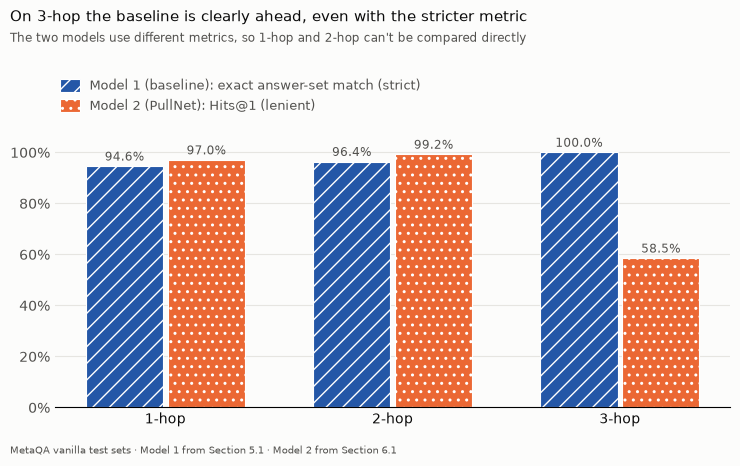

In [6]:
# Model 1: exact answer-set match on the vanilla test sets (table in Section 5.1)
try:
    disc_m1 = {int(r.hop): r.exact_set_accuracy
               for r in result_table[result_table.wording == "vanilla"].itertuples()}
except NameError:  # Section 5.1 not run in this session: use the counts it printed
    disc_m1 = {1: 9407 / 9947, 2: 14334 / 14872, 3: 14274 / 14274}
# Model 2: Hits@1 (Section 6.1)
disc_pn = {hop: s["hits@1"] for hop, s in pn_scores.items()}
disc_hops = sorted(set(disc_m1) & set(disc_pn))

print(f"{'':6}{'Model 1 exact match':>21}{'PullNet Hits@1':>16}")
for hop in disc_hops:
    print(f"{hop}-hop {100 * disc_m1[hop]:>20.2f}%{pn_pct(disc_pn[hop]):>16}")

fig, ax = plt.subplots(figsize=(7.5, 4.6), facecolor=PN_SURFACE)
pn_style(ax)
for i, (label, values, color, hatch) in enumerate([
        ("Model 1 (baseline): exact answer-set match (strict)", disc_m1, "#2457A7", "//"),
        ("Model 2 (PullNet): Hits@1 (lenient)", disc_pn, PN_ORANGE, "..")]):
    xs = [hop - 1 + (i - 0.5) * 0.36 for hop in disc_hops]
    bars = ax.bar(xs, [100 * values[hop] for hop in disc_hops], width=0.34, color=color, hatch=hatch,
                  edgecolor="white", linewidth=0.8, label=label, zorder=2)
    ax.bar_label(bars, labels=[f"{100 * values[hop]:.1f}%" for hop in disc_hops],
                 padding=2, fontsize=8.5, color=PN_INK_2)
ax.set_xticks([hop - 1 for hop in disc_hops], [f"{hop}-hop" for hop in disc_hops], color=PN_INK, fontsize=10)
ax.set_ylim(0, 110)
ax.set_yticks(range(0, 101, 20), [f"{t}%" for t in range(0, 101, 20)])
ax.legend(loc="lower left", bbox_to_anchor=(-0.01, 1.01), ncol=1, frameon=False, fontsize=9,
          labelcolor=PN_INK_2, handlelength=1.6, handleheight=1.2)
fig.suptitle("On 3-hop the baseline is clearly ahead, even with the stricter metric",
             x=0.02, ha="left", fontsize=11, color=PN_INK, y=0.975)
fig.text(0.02, 0.905, "The two models use different metrics, so 1-hop and 2-hop can't be compared directly",
         fontsize=8.5, color=PN_INK_2)
fig.text(0.02, 0.01, "MetaQA vanilla test sets · Model 1 from Section 5.1 · Model 2 from Section 6.1",
         fontsize=7.5, color=PN_INK_2)
fig.subplots_adjust(left=0.08, right=0.98, bottom=0.11, top=0.72)
fig.savefig(PN_FIG_DIR / "model_comparison_by_hop.png", dpi=200, facecolor=PN_SURFACE)
plt.show()

**What this means:** exact match is much harder to score well on than Hits@1, so the 1-hop and 2-hop bars can't be compared directly, and we don't claim either model wins there. On 3-hop the baseline is clearly ahead (100% vs 58.5%), even though its metric is the stricter one.
<!-- Lily: update these numbers after the full re-run (they come from the code outputs) -->

### 8.3 Strengths, weaknesses and future work

**Model 1 (baseline)**
- *Strengths:* exact, cheap to run, and easy to inspect, because you can see the path it followed.
- *Weaknesses:* it needs question-type labels and only works for question patterns it has seen. If one fact is missing from the graph, it gives no answer.

**Model 2 (PullNet)**
- *Strengths:* no question-type labels needed, it gives a ranked list, and it is almost perfect on 1-hop and 2-hop.
- *Weaknesses:* much weaker on 3-hop here (see 6.4).
- Because it doesn't rely on templates, PullNet *could* cope better with new wording or an incomplete graph. **We did not test this.**

**Limitations of this comparison**
- The two models are scored with different metrics.
- MetaQA's questions come from templates, so a high score doesn't show real language understanding.
- PullNet's results come from one run with default settings.

**Future work**
- The fixed 3-hop PullNet (Section 7).
- More message-passing steps, and more entities expanded per step.
- More training data.
- Testing both models on an incomplete graph.

**Reference:** Sun, H., Bedrax-Weiss, T., & Cohen, W. W. (2019). *PullNet: Open Domain Question Answering with Iterative Retrieval on Knowledge Bases and Text.* EMNLP-IJCNLP.